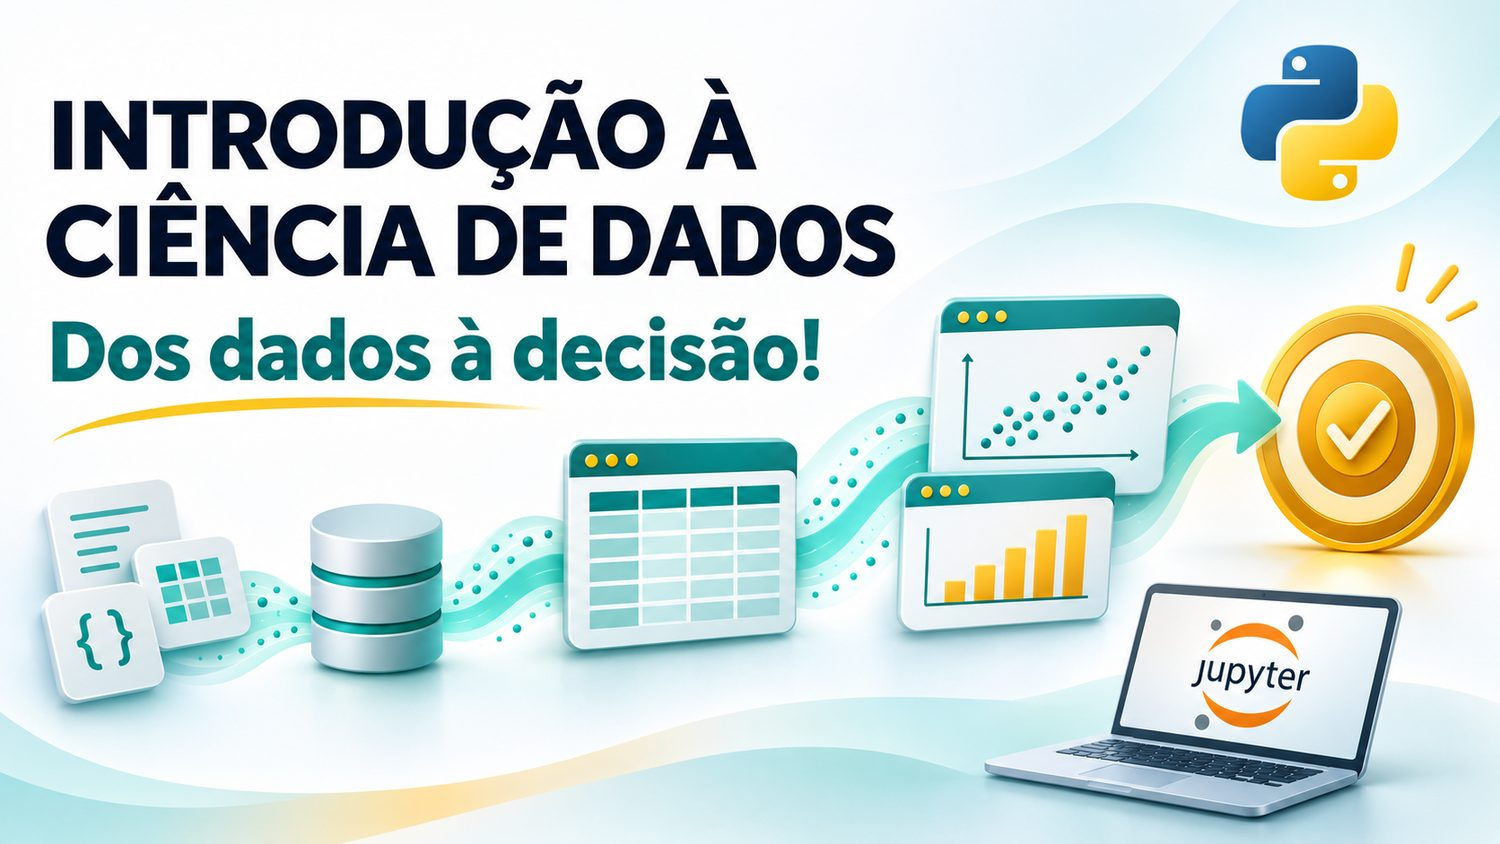

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_5_modelos_lineares/04_Regularizacao.ipynb)

# Capítulo 4 – Regularização: Ridge e Lasso

Um modelo linear com muitos atributos e poucos dados tem coeficientes a mais para a informação que há. Ajusta-se muito bem ao treino e falha em dados novos. A **regularização** é a resposta: acrescenta ao treino uma penalização para coeficientes grandes, o que obriga o modelo a ser mais contido. Este capítulo apresenta as duas formas mais usadas, Ridge e Lasso.

> **Objetivos:** reconhecer o sobreajuste num modelo linear; perceber a ideia de penalizar coeficientes; implementar a regressão Ridge de raiz; ver o efeito da força da regularização e escolhê-la com dados de validação; perceber como o Lasso seleciona atributos; saber porque é preciso normalizar; ligar a regularização ao parâmetro `C` da regressão logística.

**Pré-requisitos:** capítulos 1 a 3, e o capítulo 2 do módulo 4 (treino, validação e teste).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_instalacoes(n=1500, semente=61):
    """Gera instalações solares residenciais de uma empresa fictícia (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    potencia = rng.gamma(4.0, 1.1, n).clip(1.5, 12).round(1)
    zona = rng.choice(["norte", "centro", "sul"], n, p=[0.35, 0.4, 0.25])
    orientacao = rng.choice(["sul", "este", "oeste"], n, p=[0.55, 0.22, 0.23])
    inclinacao = rng.normal(28, 8, n).clip(5, 50).round()
    sombra = (rng.beta(1.2, 6, n) * 60).round()
    idade = rng.integers(0, 13, n)
    sol = pd.Series(zona).map({"norte": 1280, "centro": 1420, "sul": 1570}).to_numpy()              # kWh por kWp, por ano
    fator = (pd.Series(orientacao).map({"sul": 1.0, "este": 0.86, "oeste": 0.84}).to_numpy() * (1 - 0.00035 * (inclinacao - 32) ** 2)
             * (1 - 0.009 * sombra) * (1 - 0.006 * idade))
    producao = potencia * sol * fator * rng.normal(1, 0.05, n)
    return pd.DataFrame({"potencia_kwp": potencia, "zona": zona, "orientacao": orientacao, "inclinacao_graus": inclinacao,
                         "sombra_pct": sombra, "idade_anos": idade, "producao_kwh": producao.round(-1)})


instalacoes = gerar_instalacoes()
instalacoes.head()

,potencia_kwp,zona,orientacao,inclinacao_graus,sombra_pct,idade_anos,producao_kwh
0,3.0,centro,este,22.0,13.0,0,3280.0
1,1.5,sul,sul,34.0,27.0,7,1720.0
2,6.1,centro,sul,30.0,9.0,7,7850.0
3,3.0,centro,sul,28.0,2.0,7,3670.0
4,2.2,centro,sul,26.0,29.0,2,2260.0


## Poucos dados, muitos atributos

A empresa abriu uma delegação nova, que tem apenas **80 instalações** registadas. Em contrapartida, os técnicos dessa delegação preenchem uma ficha muito completa: além dos atributos que já conhecemos, registam 40 medições (marca dos cabos, cor das telhas, altura do prédio…) que **não têm relação nenhuma** com a produção. Simulamo-las com números ao acaso.

Queremos um modelo só com os dados desta delegação.

In [3]:
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(7)
numericas = ["potencia_kwp", "inclinacao_graus", "sombra_pct", "idade_anos"]
tabela = instalacoes[numericas].copy()
for zona in ["norte", "sul"]:
    tabela[f"zona_{zona}"] = (instalacoes["zona"] == zona).astype(float)
for orientacao in ["este", "oeste"]:
    tabela[f"orientacao_{orientacao}"] = (instalacoes["orientacao"] == orientacao).astype(float)
verdadeiros = list(tabela.columns)
inuteis = [f"medicao_{i:02d}" for i in range(1, 41)]
tabela[inuteis] = rng.normal(size=(len(tabela), 40))
alvo = instalacoes["producao_kwh"]

X_resto, X_teste, y_resto, y_teste = train_test_split(tabela, alvo, test_size=0.5, random_state=0)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(X_resto, y_resto, train_size=80, test_size=300, random_state=0)

media, desvio = X_treino.mean(), X_treino.std()
Z_treino, Z_validacao, Z_teste = [(X - media) / desvio for X in (X_treino, X_validacao, X_teste)]       # normalizar com o treino
print(f"Treino: {len(Z_treino)} instalações | validação: {len(Z_validacao)} | teste: {len(Z_teste)} | atributos: {Z_treino.shape[1]} ({len(verdadeiros)} com informação, {len(inuteis)} sem)")

Treino: 80 instalações | validação: 300 | teste: 750 | atributos: 48 (8 com informação, 40 sem)


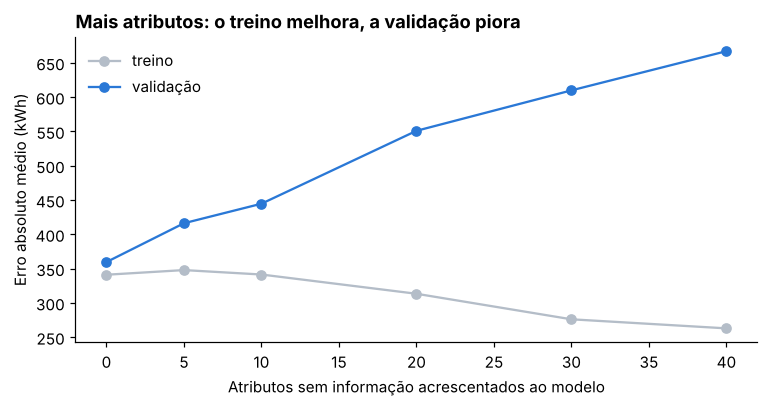

In [4]:
def mae(modelo, Z, y):
    return float(np.abs(y - modelo.predict(Z)).mean())


curva = []
for n_inuteis in [0, 5, 10, 20, 30, 40]:
    colunas = verdadeiros + inuteis[:n_inuteis]
    modelo = LinearRegression().fit(Z_treino[colunas], y_treino)
    curva.append({"atributos sem informação": n_inuteis, "treino": mae(modelo, Z_treino[colunas], y_treino), "validação": mae(modelo, Z_validacao[colunas], y_validacao)})
curva = pd.DataFrame(curva).set_index("atributos sem informação")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva.index, curva["treino"], "o-", color=CINZA, label="treino")
ax.plot(curva.index, curva["validação"], "o-", color=AZUL, label="validação")
ax.set_xlabel("Atributos sem informação acrescentados ao modelo")
ax.set_ylabel("Erro absoluto médio (kWh)")
ax.set_title("Mais atributos: o treino melhora, a validação piora")
ax.legend(frameon=False)
plt.show()

Cada coluna inútil que se acrescenta **baixa** o erro de treino e **sobe** o de validação. Com 80 instalações e 48 coeficientes para ajustar, o modelo tem liberdade suficiente para usar o acaso das medições inúteis e «explicar» particularidades de cada instalação de treino. É o **sobreajuste** de que falámos no módulo 4.

O que fazem os coeficientes mostra o problema:

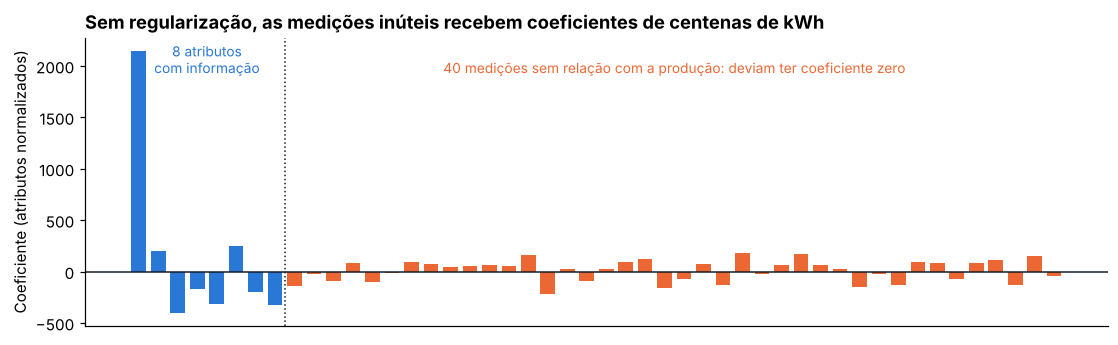

In [5]:
sem_regularizacao = LinearRegression().fit(Z_treino, y_treino)
coef_ols = pd.Series(sem_regularizacao.coef_, index=Z_treino.columns)

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(range(len(coef_ols)), coef_ols, color=[AZUL] * len(verdadeiros) + [LARANJA] * len(inuteis), width=0.75)
ax.axhline(0, color=TINTA, lw=1)
ax.axvline(len(verdadeiros) - 0.5, color=TINTA, ls=":", lw=1)
ax.text(len(verdadeiros) / 2 - 0.5, coef_ols.max() * 0.9, "8 atributos\ncom informação", ha="center", fontsize=9, color=AZUL)
ax.text(len(verdadeiros) + 19.5, coef_ols.max() * 0.9, "40 medições sem relação com a produção: deviam ter coeficiente zero", ha="center", fontsize=9, color=LARANJA)
ax.set_xticks([])
ax.set_ylabel("Coeficiente (atributos normalizados)")
ax.set_title("Sem regularização, as medições inúteis recebem coeficientes de centenas de kWh")
plt.show()

As 40 colunas à direita são ruído puro, e o seu coeficiente verdadeiro é zero. O modelo atribui a muitas delas efeitos de cem ou duzentos kWh, positivos e negativos. Cada um desses coeficientes é um pequeno erro que se soma à previsão de cada instalação nova.

## A ideia: cobrar pelos coeficientes

Os mínimos quadrados só olham para o erro no treino. A regularização muda o objetivo: passa a minimizar-se o erro **mais uma penalização** que cresce com o tamanho dos coeficientes.

> **custo = soma dos quadrados dos resíduos + α × (tamanho dos coeficientes)**

O modelo só pode dar um coeficiente grande a um atributo se isso reduzir o erro o suficiente para «pagar» a penalização. Um atributo que só explica acasos não compensa, e o seu coeficiente fica perto de zero.

O **α** (alfa) é a força da regularização: um hiperparâmetro que escolhemos. Com α = 0, voltamos aos mínimos quadrados. Com α enorme, todos os coeficientes vão para zero e o modelo prevê sempre a média.

As duas variantes diferem na forma de medir o «tamanho»:

| | Penalização | Efeito |
| --- | --- | --- |
| **Ridge** | Soma dos **quadrados** dos coeficientes | Encolhe todos, sem anular nenhum |
| **Lasso** | Soma dos **valores absolutos** dos coeficientes | Encolhe, e põe muitos exatamente a zero |

A ordenada na origem não é penalizada: não há razão para puxar para zero o nível médio das previsões.

## Ridge de raiz

A regressão Ridge tem uma fórmula quase igual à equação normal do capítulo 2. Basta somar α à diagonal de `Xᵀ X`:

> **(Xᵀ X + α I) b = Xᵀ y**

(`I` é a matriz identidade: uns na diagonal e zeros no resto.)

In [6]:
def ridge(Z, y, alfa):
    """Regressão Ridge com atributos normalizados. Devolve (ordenada na origem, coeficientes)."""
    Z, y = np.asarray(Z, dtype=float), np.asarray(y, dtype=float)
    centro_z, centro_y = Z.mean(axis=0), y.mean()
    Zc = Z - centro_z                                        # centrar: a ordenada na origem fica fora da penalização
    b = np.linalg.solve(Zc.T @ Zc + alfa * np.eye(Z.shape[1]), Zc.T @ (y - centro_y))
    return centro_y - centro_z @ b, b


b0, b = ridge(Z_treino, y_treino, alfa=10)
oficial = Ridge(alpha=10).fit(Z_treino, y_treino)
print(f"Maior diferença entre os nossos coeficientes e os do scikit-learn: {np.abs(b - oficial.coef_).max():.2e}")
print(f"Tamanho dos coeficientes (soma dos quadrados): sem regularização {np.sum(coef_ols ** 2):,.0f} | Ridge com α = 10: {np.sum(b ** 2):,.0f}".replace(",", " "))

Maior diferença entre os nossos coeficientes e os do scikit-learn: 6.82e-13
Tamanho dos coeficientes (soma dos quadrados): sem regularização 5 573 372 | Ridge com α = 10: 3 898 137


### O efeito de α

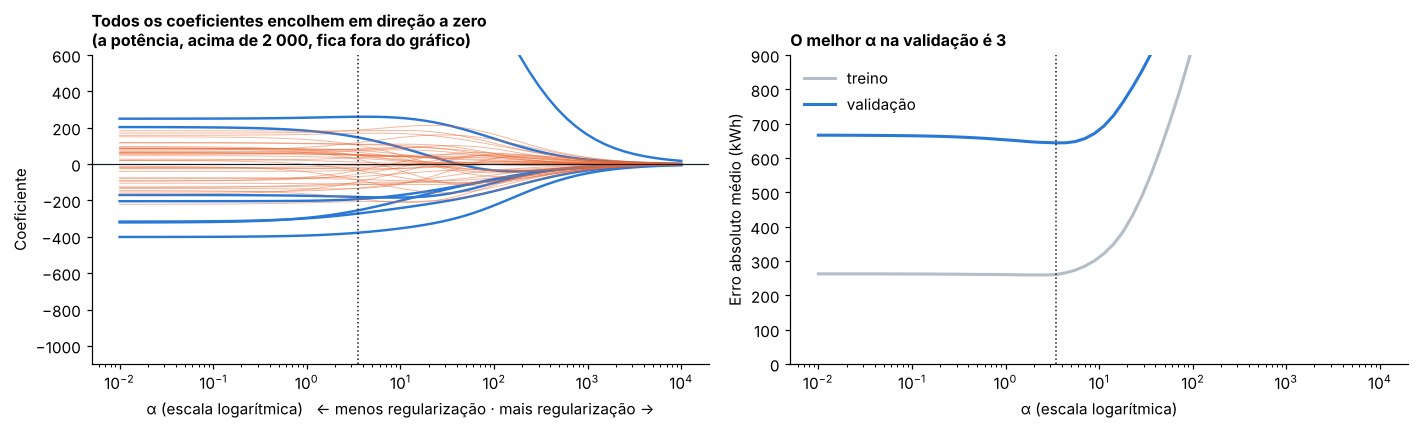

In [7]:
alfas = np.logspace(-2, 4, 60)
caminho = np.array([ridge(Z_treino, y_treino, a)[1] for a in alfas])
erros = pd.DataFrame([{"alfa": a, "treino": mae(Ridge(alpha=a).fit(Z_treino, y_treino), Z_treino, y_treino),
                       "validação": mae(Ridge(alpha=a).fit(Z_treino, y_treino), Z_validacao, y_validacao)} for a in alfas]).set_index("alfa")
melhor_alfa = float(erros["validação"].idxmin())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for j, nome in enumerate(Z_treino.columns):
    util = nome in verdadeiros
    ax1.plot(alfas, caminho[:, j], color=AZUL if util else LARANJA, lw=1.6 if util else 0.6, alpha=1 if util else 0.5)
ax1.axhline(0, color=TINTA, lw=0.8)
ax1.axvline(melhor_alfa, color=TINTA, ls=":", lw=1)
ax1.set_xscale("log")
ax1.set_ylim(-1100, 600)
ax1.set_xlabel("α (escala logarítmica)   ← menos regularização · mais regularização →")
ax1.set_ylabel("Coeficiente")
ax1.set_title("Todos os coeficientes encolhem em direção a zero\n(a potência, acima de 2 000, fica fora do gráfico)", fontsize=10.5)
ax2.plot(erros.index, erros["treino"], color=CINZA, lw=2, label="treino")
ax2.plot(erros.index, erros["validação"], color=AZUL, lw=2, label="validação")
ax2.axvline(melhor_alfa, color=TINTA, ls=":", lw=1)
ax2.set_xscale("log")
ax2.set_ylim(0, 900)
ax2.set_xlabel("α (escala logarítmica)")
ax2.set_ylabel("Erro absoluto médio (kWh)")
ax2.set_title(f"O melhor α na validação é {melhor_alfa:.0f}", fontsize=10.5)
ax2.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

À esquerda, cada linha é um coeficiente (azul para os atributos com informação, laranja para as medições inúteis). À medida que α cresce, todos são puxados para zero. Os das medições inúteis, que não tinham nada de real a sustentá-los, desaparecem depressa; os dos atributos verdadeiros resistem mais tempo.

À direita, a consequência. O erro de treino **sobe sempre** com α: o modelo tem cada vez menos liberdade. O de validação desce um pouco, atinge um mínimo e sobe depressa quando a regularização é tão forte que encolhe também os coeficientes que interessam.

O ganho é aqui **pequeno**, e o gráfico da esquerda mostra porquê: o Ridge encolhe todos os coeficientes na mesma proporção, os úteis e os inúteis. Para apagar os 40 inúteis teria de estragar o da potência, que é o que mais conta. O Ridge funciona melhor quando muitos atributos contribuem um pouco cada um; o nosso problema é o contrário, com poucos atributos importantes no meio de muitos sem valor.

O α escolhe-se como qualquer hiperparâmetro: pelo erro em dados de **validação**, nunca pelo de treino (que escolheria sempre α = 0). No módulo 6 veremos uma forma mais robusta de fazer esta escolha, a validação cruzada.

## Lasso: regularizar e selecionar

O Lasso usa o valor absoluto em vez do quadrado. Parece um pormenor, e muda o comportamento: em vez de aproximar os coeficientes de zero, **anula** muitos deles por completo. O modelo final usa só uma parte dos atributos.

Não tem fórmula fechada (o valor absoluto não tem derivada em zero); usamos a implementação do scikit-learn.

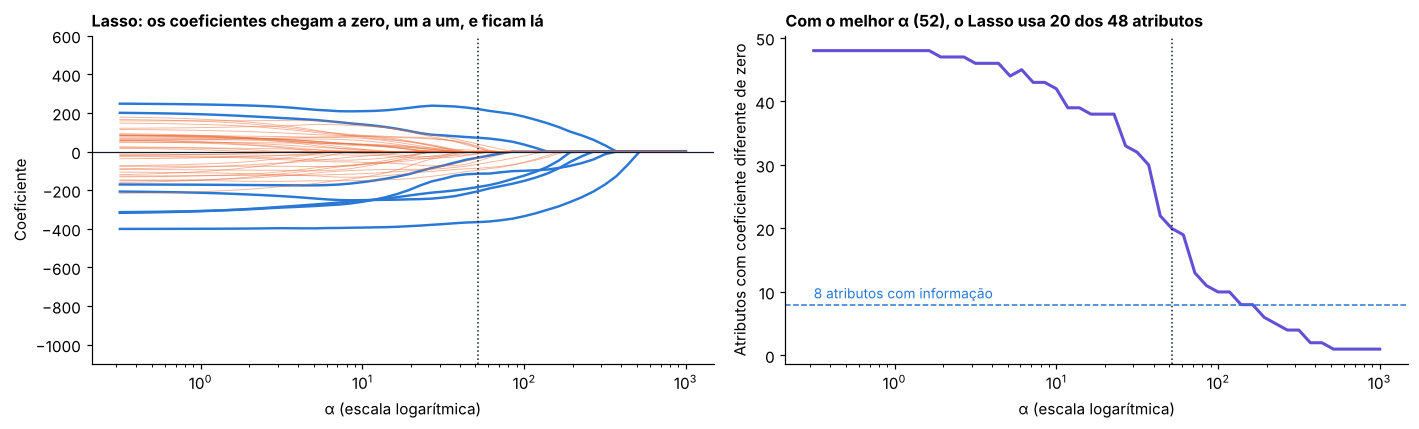

In [8]:
alfas_lasso = np.logspace(-0.5, 3, 50)
caminho_lasso = np.array([Lasso(alpha=a, max_iter=50_000).fit(Z_treino, y_treino).coef_ for a in alfas_lasso])
erros_lasso = pd.Series({a: mae(Lasso(alpha=a, max_iter=50_000).fit(Z_treino, y_treino), Z_validacao, y_validacao) for a in alfas_lasso})
melhor_lasso = float(erros_lasso.idxmin())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for j, nome in enumerate(Z_treino.columns):
    util = nome in verdadeiros
    ax1.plot(alfas_lasso, caminho_lasso[:, j], color=AZUL if util else LARANJA, lw=1.6 if util else 0.6, alpha=1 if util else 0.5)
ax1.axhline(0, color=TINTA, lw=0.8)
ax1.axvline(melhor_lasso, color=TINTA, ls=":", lw=1)
ax1.set_xscale("log")
ax1.set_ylim(-1100, 600)
ax1.set_xlabel("α (escala logarítmica)")
ax1.set_ylabel("Coeficiente")
ax1.set_title("Lasso: os coeficientes chegam a zero, um a um, e ficam lá", fontsize=10.5)
usados = (caminho_lasso != 0).sum(axis=1)
ax2.plot(alfas_lasso, usados, color=VIOLETA, lw=2)
ax2.axvline(melhor_lasso, color=TINTA, ls=":", lw=1)
ax2.axhline(len(verdadeiros), color=AZUL, ls="--", lw=1)
ax2.text(alfas_lasso[0], len(verdadeiros) + 1, "8 atributos com informação", ha="left", fontsize=9, color=AZUL)
ax2.set_xscale("log")
ax2.set_xlabel("α (escala logarítmica)")
ax2.set_ylabel("Atributos com coeficiente diferente de zero")
ax2.set_title(f"Com o melhor α ({melhor_lasso:.0f}), o Lasso usa {int((Lasso(alpha=melhor_lasso, max_iter=50_000).fit(Z_treino, y_treino).coef_ != 0).sum())} dos 48 atributos", fontsize=10.5)
plt.tight_layout()
plt.show()

In [9]:
lasso = Lasso(alpha=melhor_lasso, max_iter=50_000).fit(Z_treino, y_treino)
escolhidos = pd.Series(lasso.coef_, index=Z_treino.columns)
escolhidos = escolhidos[escolhidos != 0]
print("Atributos com informação que o Lasso manteve:", [n for n in escolhidos.index if n in verdadeiros])
print("Atributos com informação que o Lasso eliminou:", [n for n in verdadeiros if n not in escolhidos.index])
print("Medições inúteis que ficaram no modelo:", len([n for n in escolhidos.index if n in inuteis]), "de 40")

Atributos com informação que o Lasso manteve: ['potencia_kwp', 'inclinacao_graus', 'sombra_pct', 'idade_anos', 'zona_norte', 'zona_sul', 'orientacao_este', 'orientacao_oeste']
Atributos com informação que o Lasso eliminou: []
Medições inúteis que ficaram no modelo: 12 de 40


O Lasso fez uma **seleção de atributos**: eliminou 28 das 40 medições inúteis e manteve os oito atributos que explicam a produção. Não é perfeito: com 80 instalações, uma dúzia de medições ao acaso ainda passa, com coeficientes pequenos. Noutros casos, um atributo verdadeiro de efeito fraco pode ser sacrificado.

O resultado é um modelo mais pequeno, mais fácil de explicar e mais barato de usar: deixa de ser preciso recolher as medições eliminadas.

## Os três modelos, lado a lado

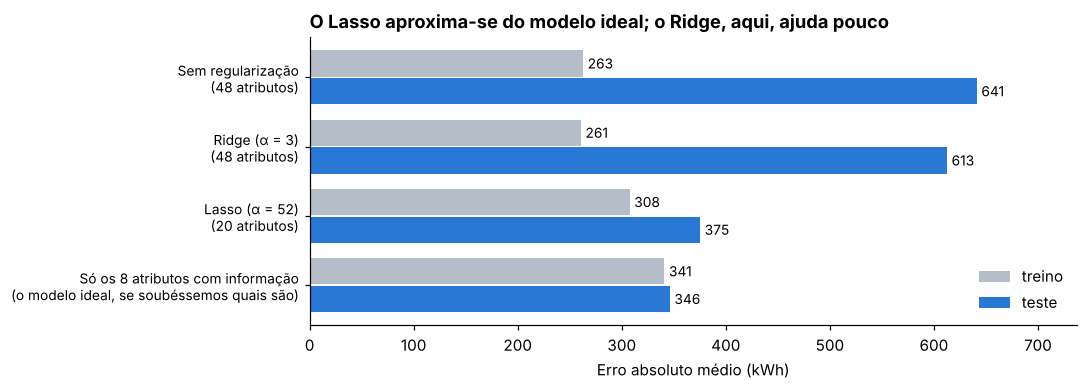

In [10]:
modelos = {"Sem regularização": sem_regularizacao, f"Ridge (α = {melhor_alfa:.0f})": Ridge(alpha=melhor_alfa).fit(Z_treino, y_treino),
           f"Lasso (α = {melhor_lasso:.0f})": lasso, "Só os 8 atributos com informação\n(o modelo ideal, se soubéssemos quais são)": None}
ideal = LinearRegression().fit(Z_treino[verdadeiros], y_treino)
linhas = []
for nome, modelo in modelos.items():
    if modelo is None:
        linhas.append({"Modelo": nome, "treino": mae(ideal, Z_treino[verdadeiros], y_treino), "teste": mae(ideal, Z_teste[verdadeiros], y_teste), "atributos usados": 8})
    else:
        linhas.append({"Modelo": nome, "treino": mae(modelo, Z_treino, y_treino), "teste": mae(modelo, Z_teste, y_teste), "atributos usados": int((modelo.coef_ != 0).sum())})
comparacao = pd.DataFrame(linhas).set_index("Modelo")

fig, ax = plt.subplots(figsize=(9, 3.4))
posicoes = np.arange(len(comparacao))
b1 = ax.barh(posicoes - 0.2, comparacao["treino"], 0.38, color=CINZA, label="treino")
b2 = ax.barh(posicoes + 0.2, comparacao["teste"], 0.38, color=AZUL, label="teste")
ax.bar_label(b1, fmt="%.0f", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.0f", padding=3, fontsize=9)
ax.set_yticks(posicoes, [f"{n}\n({k} atributos)" if "\n" not in n else n for n, k in zip(comparacao.index, comparacao["atributos usados"])], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, comparacao["teste"].max() * 1.15)
ax.set_xlabel("Erro absoluto médio (kWh)")
ax.set_title("O Lasso aproxima-se do modelo ideal; o Ridge, aqui, ajuda pouco")
ax.legend(frameon=False, loc="lower right")
plt.show()

O modelo sem regularização tem um erro de teste mais do dobro do de treino. O Ridge melhora pouco, pela razão que vimos. O Lasso, que elimina colunas inúteis em vez de apenas as atenuar, erra mais no treino e muito menos no teste: troca ajuste aos dados de treino por desempenho em dados novos, e fica perto do modelo ideal.

A última barra é o que conseguiríamos se soubéssemos à partida que colunas interessam. Na prática não sabemos, e a regularização é uma forma de deixar os dados dizê-lo.

| | Ridge | Lasso |
| --- | --- | --- |
| Penaliza | Os quadrados dos coeficientes | Os valores absolutos |
| Coeficientes | Todos pequenos, nenhum a zero | Muitos exatamente a zero |
| Bom quando | Muitos atributos contribuem um pouco; atributos correlacionados | Poucos atributos importam; quer-se um modelo pequeno |
| Com atributos muito correlacionados | Reparte o efeito entre eles | Escolhe um e anula os outros, de forma algo arbitrária |
| Cálculo | Fórmula direta | Iterativo |

Há uma combinação das duas, a **Elastic Net** (`ElasticNet` no scikit-learn), que soma as duas penalizações.

## Porque é obrigatório normalizar

A penalização soma os coeficientes de todos os atributos como se fossem comparáveis. Não são, se as unidades forem diferentes.

Exprimimos a potência em **watts-pico** em vez de quilowatts-pico. Os dados são os mesmos; o coeficiente dos mínimos quadrados passa a ser mil vezes menor (1,1 kWh por Wp em vez de 1 100 por kWp), e as previsões não mudam. Com regularização, mudam.

In [11]:
colunas = ["potencia_kwp", "sombra_pct"]
em_kw, em_w = X_treino[colunas], X_treino[colunas].assign(potencia_kwp=X_treino["potencia_kwp"] * 1000)
teste_kw, teste_w = X_teste[colunas], X_teste[colunas].assign(potencia_kwp=X_teste["potencia_kwp"] * 1000)
linhas = {}
for nome, modelo in [("Mínimos quadrados", LinearRegression), ("Ridge (α = 100), sem normalizar", lambda: Ridge(alpha=100))]:
    linhas[nome] = {"MAE no teste, potência em kWp": mae(modelo().fit(em_kw, y_treino), teste_kw, y_teste),
                    "MAE no teste, potência em Wp": mae(modelo().fit(em_w, y_treino), teste_w, y_teste)}
pd.DataFrame(linhas).T.round(0)

,"MAE no teste, potência em kWp","MAE no teste, potência em Wp"
Mínimos quadrados,573.0,573.0
"Ridge (α = 100), sem normalizar",685.0,571.0


Os mínimos quadrados dão o mesmo resultado nas duas unidades. O Ridge sem normalização, não: com a potência em kWp, o coeficiente é grande (cerca de 1 100) e é fortemente penalizado; em Wp é pequeno (1,1) e quase não paga nada. A mesma informação é tratada de forma diferente só por causa da unidade.

> **Antes de regularizar, normaliza-se.** Com todos os atributos em desvios-padrão, a penalização trata-os por igual. E, como sempre, a média e o desvio-padrão aprendem-se com o treino, dentro de um pipeline.

## A regularização na regressão logística

A regressão logística do capítulo 3 regulariza-se da mesma maneira: soma-se a penalização à perda logarítmica. No scikit-learn, o parâmetro chama-se **`C`** e funciona **ao contrário** de α:

> **C = 1 ÷ α.** Um `C` pequeno é muita regularização; um `C` grande é pouca.

O valor por omissão é `C = 1`: a `LogisticRegression` do scikit-learn **regulariza sempre**, a menos que se peça o contrário. Foi por isso que usámos `C=1e6` no capítulo 3, para comparar com a nossa implementação.

Há um caso em que a regularização é indispensável. Quando as classes são **perfeitamente separáveis** (existe uma fronteira que não erra nenhum caso de treino), a perda logarítmica pode sempre baixar mais um pouco aumentando os coeficientes, e eles crescem sem limite (na prática, até o algoritmo desistir).

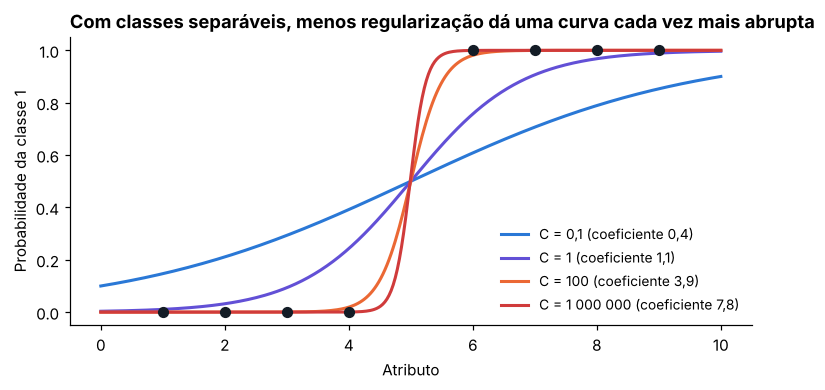

In [12]:
from sklearn.linear_model import LogisticRegression

x = np.array([1.0, 2, 3, 4, 6, 7, 8, 9]).reshape(-1, 1)
classe = np.array([0, 0, 0, 0, 1, 1, 1, 1])                   # separáveis: tudo o que é menor do que 5 é da classe 0
eixo = np.linspace(0, 10, 300).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.scatter(x, classe, color=TINTA, zorder=3, s=40)
for C, rotulo, cor in [(0.1, "0,1", AZUL), (1, "1", VIOLETA), (100, "100", LARANJA), (1e6, "1 000 000", MAU)]:
    modelo = LogisticRegression(C=C, max_iter=10_000).fit(x, classe)
    ax.plot(eixo, modelo.predict_proba(eixo)[:, 1], color=cor, lw=2, label=f"C = {rotulo} (coeficiente {modelo.coef_[0, 0]:.1f})".replace(".", ","))
ax.set_xlabel("Atributo")
ax.set_ylabel("Probabilidade da classe 1")
ax.set_title("Com classes separáveis, menos regularização dá uma curva cada vez mais abrupta")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.show()

Sem regularização, a curva torna-se um degrau: o modelo passa de 0% para 100% de certeza num instante, com base em oito pontos. Com regularização, a transição é gradual, e a incerteza junto à fronteira fica representada. Com muitos atributos e poucos dados, a separação perfeita aparece facilmente por acaso.

## Quando usar

| Situação | Recomendação |
| --- | --- |
| Muitos atributos em relação ao número de observações | Regularizar sempre |
| Atributos muito correlacionados (capítulo 2) | Ridge estabiliza os coeficientes |
| Quer-se saber que atributos interessam, ou reduzir os que se recolhem | Lasso |
| Muitos dados e poucos atributos | Pouca diferença; uma regularização fraca não faz mal |
| Quer-se interpretar os coeficientes com rigor | Cuidado: a regularização **enviesa-os** para zero, de propósito |

A última linha é importante. A regularização troca coeficientes «certos em média, mas instáveis» por coeficientes «um pouco pequenos de mais, mas estáveis». Para prever, é quase sempre um bom negócio. Para medir o efeito de um atributo, é preciso lembrar que os valores foram encolhidos.

## Exercícios

### `Exercício 1` – O custo de dois modelos

Dois modelos têm a mesma soma dos quadrados dos resíduos, 1 000. O modelo A tem os coeficientes (3, 4); o modelo B tem (5, 0). Calcula o custo total de cada um com a penalização Ridge e com a penalização Lasso, para α = 10. Qual prefere cada método?

<details>
<summary><b>Ver uma solução possível</b></summary>

- **Ridge** (quadrados): A = 9 + 16 = 25; B = 25 + 0 = 25. Custos: 1 000 + 10 × 25 = **1 250** para os dois. O Ridge é indiferente.
- **Lasso** (valores absolutos): A = 3 + 4 = 7; B = 5 + 0 = 5. Custos: **1 070** para A e **1 050** para B. O Lasso prefere B.

Os dois vetores têm o mesmo «comprimento» (5), que é o que o Ridge mede. O Lasso mede a soma dos valores absolutos, que é menor quando o peso está concentrado num só coeficiente. É por isso que o Lasso produz zeros.

</details>

### `Exercício 2` – Mais dados, menos regularização

Repete a escolha de α para o Ridge com um treino de 400 instalações em vez de 80 (tira-as de `X_resto`, e usa as restantes para validar). O melhor α é maior ou menor? A diferença entre o modelo sem regularização e o Ridge, na validação, aumenta ou diminui?

In [13]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for n in [80, 400]:
    Xt, Xv, yt, yv = train_test_split(X_resto, y_resto, train_size=n, test_size=300, random_state=0)
    m, d = Xt.mean(), Xt.std()
    Zt, Zv = (Xt - m) / d, (Xv - m) / d
    erros_n = {a: mae(Ridge(alpha=a).fit(Zt, yt), Zv, yv) for a in np.logspace(-2, 4, 60)}
    melhor = min(erros_n, key=erros_n.get)
    print(f"treino de {n:>3}: sem regularização {mae(LinearRegression().fit(Zt, yt), Zv, yv):.0f} kWh | melhor Ridge {erros_n[melhor]:.0f} kWh (α = {melhor:.1f})")
```

Com 400 instalações, o modelo sem regularização já é muito melhor, e o Ridge não acrescenta nada: o melhor α é praticamente zero. Com mais dados, cada coeficiente é estimado com mais segurança e os acasos pesam menos. A regularização é sobretudo um remédio para a falta de dados em relação ao número de atributos.

</details>

### `Exercício 3` – Ridge e a colinearidade

No capítulo 2, juntar o número de painéis à potência tornou o coeficiente da potência instável. Repete essa experiência (200 amostras de 300 instalações, com as colunas `potencia_kwp` e `n_paineis` normalizadas) comparando `LinearRegression` com `Ridge(alpha=10)`. Compara o desvio-padrão do coeficiente da potência nos dois casos.

In [14]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
dados = instalacoes.assign(n_paineis=(instalacoes["potencia_kwp"] / 0.4 + np.random.default_rng(1).normal(0, 0.6, len(instalacoes))).round())
resultados = {"mínimos quadrados": [], "Ridge": []}
for semente in range(200):
    a = dados.sample(300, random_state=semente)
    Za = (a[["potencia_kwp", "n_paineis"]] - a[["potencia_kwp", "n_paineis"]].mean()) / a[["potencia_kwp", "n_paineis"]].std()
    resultados["mínimos quadrados"].append(LinearRegression().fit(Za, a["producao_kwh"]).coef_)
    resultados["Ridge"].append(Ridge(alpha=10).fit(Za, a["producao_kwh"]).coef_)
for nome, valores in resultados.items():
    valores = np.array(valores)
    print(f"{nome:>18}: potência {valores[:, 0].mean():>6.0f} ± {valores[:, 0].std():.0f} | n.º de painéis {valores[:, 1].mean():>6.0f} ± {valores[:, 1].std():.0f}")
```

Com os mínimos quadrados, os dois coeficientes variam muito de amostra para amostra (o que um ganha, o outro perde). Com o Ridge, ficam os dois perto de metade do efeito total e variam muito menos: perante duas colunas quase iguais, o Ridge **reparte** o efeito entre elas, porque dois coeficientes médios pagam menos penalização do que um grande e outro de sinal contrário.

</details>

### `Exercício 4` – O valor de C

Usa os orçamentos do capítulo 3 (copia a função `gerar_orcamentos`), mas treina só com **60 orçamentos** e as colunas `anos_retorno`, `fatura_mensal` e `idade_casa` normalizadas, mais 30 colunas de ruído. Compara a perda logarítmica (`sklearn.metrics.log_loss`) numa validação de 1 000 orçamentos para `C` = 0,01; 0,1; 1; 10 e 1 000 000.

In [15]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.metrics import log_loss

g = np.random.default_rng(83)
n = 4000
fatura = g.gamma(4.0, 22, n).clip(25, 400)
anos = (g.normal(8.5, 2.2, n) - 0.008 * (fatura - 90)).clip(3, 16)
idade_casa = g.integers(1, 60, n)
aceitou = g.random(n) < 1 / (1 + np.exp(-(-0.5 - 0.42 * (anos - 8) + 0.004 * (fatura - 90))))
A = np.column_stack([anos, fatura, idade_casa, g.normal(size=(n, 30))])
A = (A - A[:60].mean(axis=0)) / A[:60].std(axis=0)
for C in [0.01, 0.1, 1, 10, 1e6]:
    m = LogisticRegression(C=C, max_iter=10_000).fit(A[:60], aceitou[:60])
    print(f"C = {C:>9g}: perda no treino {log_loss(aceitou[:60], m.predict_proba(A[:60])[:, 1]):.3f} | na validação {log_loss(aceitou[60:1060], m.predict_proba(A[60:1060])[:, 1]):.3f}")
```

(Para a solução ser curta, gerámos aqui uma versão simplificada dos orçamentos.) Com `C` muito grande, a perda de treino é praticamente zero: com 33 atributos e 60 pontos, as classes são separáveis, e o modelo fica com certezas absolutas. Na validação, essas certezas erradas custam uma perda enorme. O melhor valor está nos `C` pequenos: é mais um caso em que o desempenho no treino aponta para o lado errado.

</details>

## Resumo do módulo, até aqui

| Capítulo | Modelo | Ideia central |
| --- | --- | --- |
| 1 | Regressão linear simples | A reta que minimiza a soma dos quadrados dos resíduos |
| 2 | Regressão linear múltipla | Uma soma ponderada; cada coeficiente lê-se «mantendo o resto constante» |
| 3 | Regressão logística | A mesma soma, passada pela sigmoide, dá uma probabilidade |
| 4 | Ridge e Lasso | Penalizar coeficientes grandes para o modelo não aprender acasos |

## Verifica o que aprendeste

- [ ] Sei reconhecer o sobreajuste num modelo linear com muitos atributos.
- [ ] Sei explicar a ideia de penalizar os coeficientes.
- [ ] Sei implementar a regressão Ridge.
- [ ] Sei o que acontece aos coeficientes e aos erros quando α aumenta.
- [ ] Sei escolher α com dados de validação.
- [ ] Sei a diferença entre Ridge e Lasso, e quando usar cada um.
- [ ] Sei porque é obrigatório normalizar antes de regularizar.
- [ ] Sei o que é o parâmetro `C` da regressão logística.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification
- https://scikit-learn.org/stable/modules/linear_model.html#lasso
- https://en.wikipedia.org/wiki/Ridge_regression
- https://en.wikipedia.org/wiki/Lasso_(statistics)